In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

URL = "https://raw.githubusercontent.com/kb22/Heart-Disease-Prediction/master/dataset.csv"
df = pd.read_csv(URL)
X = df.drop(columns="target")
y = df["target"]

# test_size=0.3 (70% train: 212 ta, 30% test: 91 ta)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 04_cheklovsiz.py
model_not_pruned = DecisionTreeClassifier(random_state=42)
model_not_pruned.fit(X_tr, y_tr)
# train va test natijalarini o'zgaruvchiga tenglab oldim.
result_not_pruned_test = model_not_pruned.score(X_te, y_te)
result_not_pruned_train = model_not_pruned.score(X_tr, y_tr)

# 05_pre_pruning.py
model_pruned = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=42)
model_pruned.fit(X_tr, y_tr)
# train va test natijalarini o'zgaruvchiga tenglab oldim.
result_pruned_test = model_pruned.score(X_te, y_te)
result_pruned_train = model_pruned.score(X_tr, y_tr)

# 06_grid_search.py
print("======= Cheklovsiz model ===")
print(f"Train: {result_not_pruned_train:.3f} | Test: {result_not_pruned_test:.3f}")
print(f"Orasidagi farq: {(result_not_pruned_train - result_not_pruned_test):.3f}")

print("\n======== Pre-pruning modeli (max_depth=3, min_samples_leaf=10) ==================")
print(f"Train: {result_pruned_train:.3f} | Test: {result_pruned_test:.3f}")
print(f"Orasidagi farq: {(result_pruned_train - result_pruned_test):.3f}")


# bunda test_size ni 0.3 qilganimizda, trainda 212 ta va testda 91 ta qoldi.
# train aniqligi 100%, test aniqligi esa 71.4% deyarli o'zgarmadi. yani overfitting bo'lib qolgan.
# Pre-pruning qo'llaganimizdan keyin train 85%, test esa 76% ni ko'rsatib orasidagi farq ancha kichraydi.

======= Cheklovsiz model ===
Train: 1.000 | Test: 0.725
Orasidagi farq: 0.275

======== Pre-pruning modeli (max_depth=3, min_samples_leaf=10) ==================
Train: 0.858 | Test: 0.769
Orasidagi farq: 0.089


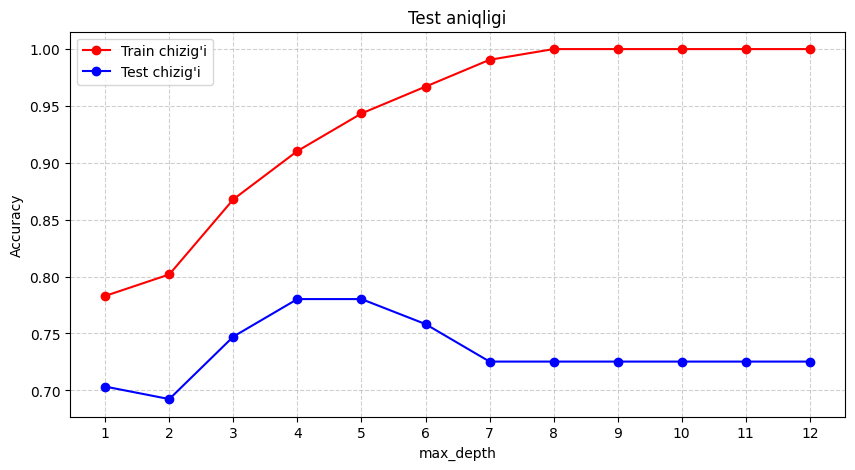

In [17]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

depths = range(1, 13)
train_scores = []
test_scores = []

for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=42)
    clf.fit(X_tr, y_tr)
    train_scores.append(clf.score(X_tr, y_tr))
    test_scores.append(clf.score(X_te, y_te))

# Grafikni chizish
plt.figure(figsize=(10, 5))
plt.plot(depths, train_scores, marker='o', color='red', label="Train chizig'i")
plt.plot(depths, test_scores, marker='o', color='blue', label="Test chizig'i")
plt.title("Test aniqligi")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.xticks(depths)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()

# max_depth 4 va 5 bo'lganda test aniqligi eng yuqori nuqtaga chiqadi.
# buni sababi: boshida yani max_depth 1 va 3 bo'lganda model endi o'rganayotgan bo'ladi
# to'liq tushunmaydi, keyin 4 va 5 bo'lganda, yaxshi tushunadi, keyin 5 dan keyin
# yana model qanchadir miqdorda yoshlashga o'tadi(overfitting boshlanadi)
# shuning uchun yana aniqlik pastga tushadi.

In [22]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

titanic_url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
data = pd.read_csv(titanic_url)

# Asosiy belgilarni tanlaymiz va tozalaymiz
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare"]
data = data[features + ["Survived"]].dropna()
data["Sex"] = data["Sex"].map({"male": 0, "female": 1})

X_t = data[features]
y_t = data["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X_t, y_t, test_size=0.25, random_state=42, stratify=y_t
)

# 2. Cheklovsiz daraxt (Overfitting'ni topamiz)
dt_full = DecisionTreeClassifier(random_state=42)
dt_full.fit(X_train, y_train)

print("=== 1. Cheklovsiz daraxt ===")
print(f"Train aniqligi: {dt_full.score(X_train, y_train):.3f}")  # ~0.985
print(f"Test aniqligi:  {dt_full.score(X_test, y_test):.3f}")   # ~0.765
print(f"Farq: {dt_full.score(X_train, y_train) - dt_full.score(X_test, y_test):.3f} ")
# Katta farq (0.28) bo'lyapti yani Overfitting.

# 3. min_samples_leaf bilan overfitting'ni kamaytirish
dt_tuned = DecisionTreeClassifier(min_samples_leaf=15, random_state=42)
dt_tuned.fit(X_train, y_train)

print("\n=== 2. min_samples_leaf=15 qo'llangach ===")
print(f"Train aniqligi: {dt_tuned.score(X_train, y_train):.3f}")  # ~0.835
print(f"Test aniqligi:  {dt_tuned.score(X_test, y_test):.3f}")   # ~0.804
print(f"Farq: {dt_tuned.score(X_train, y_train) - dt_tuned.score(X_test, y_test):.3f} ")
# Kichik farq (0.033) bu yaxshi holatga keldi.

=== 1. Cheklovsiz daraxt ===
Train aniqligi: 0.991
Test aniqligi:  0.709
Farq: 0.281 

=== 2. min_samples_leaf=15 qo'llangach ===
Train aniqligi: 0.832
Test aniqligi:  0.799
Farq: 0.033 


In [25]:
from sklearn.tree import export_text

# max_depth=2 qilib kichik daraxt chiqaramiz
simple_tree = DecisionTreeClassifier(max_depth=2, random_state=42)
simple_tree.fit(X_train, y_train)

print(export_text(simple_tree, feature_names=list(X_t.columns)))
# bunda 1) agar erkak kishi bo'lsa va yoshi 9.5 dan kichik bo'lsa, omon qoladi deydi
# chunki yosh bolalar qutqaruv qayiqlariga chiqariladi.
# 2) agar erkak kishi bo'lsa va yoshi 9.5 dan kichik bo'lsa, xalok bo'ladi
# 3) agar ayol kishi bo'lsa va olgan chiptasini 1 va 2-class dan olgan bo'lsa
# tirik qoladi deydi model.

|--- Sex <= 0.50
|   |--- Age <= 9.50
|   |   |--- class: 1
|   |--- Age >  9.50
|   |   |--- class: 0
|--- Sex >  0.50
|   |--- Pclass <= 2.50
|   |   |--- class: 1
|   |--- Pclass >  2.50
|   |   |--- class: 0

